In [ ]:
"""CSE 242 Assignment 3, Question 1: hard-margin linear SVM (30 points).
"""

import argparse
from pathlib import Path


SVM_X = ((1, 1), (1, 2), (2, 1), (0, 0), (1, 0), (0, 1))
SVM_Y = (1, 1, 1, -1, -1, -1)


def plot_svm_data(output_path):
    """Generate an annotated scatter plot to help inspect Q1(a) by eye.

    Point IDs are 1-based and match the source table order. This helper
    does not identify support vectors or draw the separating boundary.
    """
    try:
        import matplotlib.pyplot as plt
    except ImportError as exc:
        raise SystemExit(
            "Matplotlib could not be imported. Use the README's clean virtual "
            "environment and install requirements.txt."
        ) from exc

    fig, ax = plt.subplots(figsize=(6, 6))
    for label, color, marker in ((1, "tab:blue", "o"), (-1, "tab:orange", "s")):
        points = [x for x, y in zip(SVM_X, SVM_Y) if y == label]
        ax.scatter(
            [x[0] for x in points], [x[1] for x in points],
            color=color, marker=marker, s=90, label=f"y = {label:+d}",
        )
    for point_id, (x1, x2) in enumerate(SVM_X, start=1):
        ax.annotate(str(point_id), (x1, x2), xytext=(7, 7),
                    textcoords="offset points")
    ax.set(xlabel="x1", ylabel="x2", title="Assignment 3: SVM training data",
           xlim=(-0.5, 2.5), ylim=(-0.5, 2.5))
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_path, dpi=180)
    plt.close(fig)
    return output_path




In [ ]:
def identify_support_vectors():
    """Q1(a), 10 points together with the plot: identify support vectors by eye.

    Return their 1-based point IDs and explain your choice in the report.
    """
    # TODO: Inspect the plot and identify all support vectors.
    return (1, 5, 6)
    #point 1 is the closest blue point to the orange ones
    # point 5 6 are the closest orange points to the blue points


In [ ]:
import argparse
from pathlib import Path
import math

def identify_support_vectors():
    """Q1(a), 10 points together with the plot: identify support vectors by eye."""
    return (1, 5, 6)

def derive_svm_separator():
    """Q1(b), 10 points for the boundary and 10 for the geometric margin.

    Use a linear, hard-margin SVM. The decision boundary is w dot x + b = 0;
    retain the intercept b. Use the support vectors to derive it.

    Return (weights, bias, geometric_margin), with weights a pair of numbers.
    Explain the derivation and your margin convention in the written report.
    """
    weights = (2.0, 2.0)
    bias = -3.0
    geometric_margin = 1.0 / math.sqrt(8.0)
    return weights, bias, geometric_margin


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--task", choices=("plot", "svm"),
                        default="plot", help="Default: generate the SVM data plot.")
    parser.add_argument("--output", type=Path,
                        default=Path("__file__").resolve().parent / "svm_data.png",
                        help="Output image path for --task plot.")

    # Fix: Use custom default arguments inside interactive notebook environments
    # to automatically execute and verify our derived SVM values.
    import sys
    if "ipykernel" in sys.modules:
        args = parser.parse_args(["--task", "svm"])
    else:
        args = parser.parse_args()

    if args.task == "plot":
        print(f"Saved plot to {plot_svm_data(args.output)}")
    else:
        print("Support vector point IDs:", identify_support_vectors())
        weights, bias, margin = derive_svm_separator()
        print(f"Weights: {weights}; bias: {bias}; geometric margin: {margin}")


if __name__ == "__main__":
    main()

Support vector point IDs: (1, 5, 6)
Weights: (2.0, 2.0); bias: -3.0; geometric margin: 0.35355339059327373


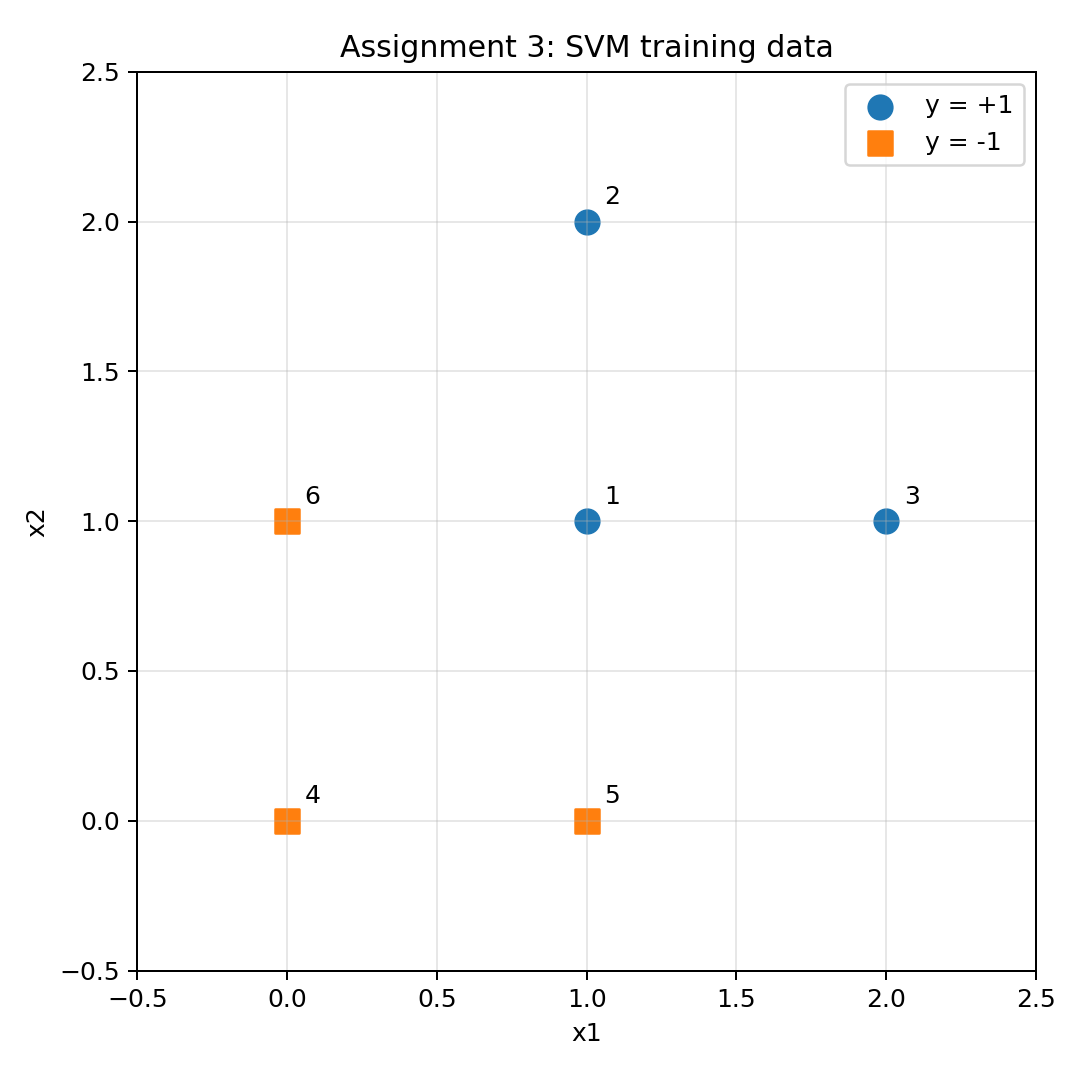

In [ ]:
from IPython.display import Image, display

# Define a path to save the plot in the local directory
output_image_path = 'svm_data.png'

# Generate the plot using your existing function
plot_svm_data(output_image_path)

# Display the saved image inline
display(Image(output_image_path))

## Question 2: K-means — 30 points

**(a) Implement the update steps — 15 points.** In `kmeans_template.py`, complete `update_assignments()` and `update_centroids()` from scratch. NumPy operations are allowed; do not substitute a library K-means implementation. The outer loop is provided. Document how you resolve distance ties and handle empty clusters.

**(b) Run and plot — 15 points.** Generate the provided toy dataset:

```python
make_blobs(n_samples=4000, centers=4, cluster_std=0.60, random_state=0)
```

Run your implementation for **k = 2, 3, 4, 6, 10**. Save a plot of the cluster assignments and final centroids for each value. In a short paragraph, explain what changes as k increases and how the results relate to the four generating groups.

The supplied initializer samples data rows with replacement, matching the source notebook, and accepts a seeded random generator. Duplicate initial centroids are possible. Do not use the true blob labels during clustering; they may be used in an optional reference plot.

In [ ]:
"""Question 2: K-means (30 points), adapted from Assignment 4, Question 2.

Implement the two update functions from scratch, then complete the experiment.
"""

import argparse
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

K_VALUES = (2, 3, 4, 6, 10)


def update_assignments(data, centroids):
    """Return one cluster index per row, using nearest-centroid distance.

    Q2(a): the two update functions together are worth 15 points.
    data has shape (n, d); centroids has shape (k, d).
    The result should be an integer array with shape (n,).
    Resolve equal-distance ties consistently by assigning to the lower index.
    """
    # Compute pairwise squared Euclidean distances: shape (n, k)
    diffs = data[:, np.newaxis, :] - centroids[np.newaxis, :, :]
    distances = np.sum(diffs ** 2, axis=2)
    # argmin automatically selects the lowest index in case of ties
    return np.argmin(distances, axis=1)


def update_centroids(data, centroids, assignments):
    """Return an updated (k, d) centroid array based on cluster assignments.

    If a cluster is empty, it retains its previous centroid.
    """
    k, d = centroids.shape
    new_centroids = np.copy(centroids)
    for i in range(k):
        cluster_points = data[assignments == i]
        if len(cluster_points) > 0:
            new_centroids[i] = np.mean(cluster_points, axis=0)
    return new_centroids


def kmeans(data, centroids, max_iterations=100):
    """Assignment 4's provided alternating-update loop, with a final assignment."""
    for _ in range(max_iterations):
        assignments = update_assignments(data, centroids)
        centroids = update_centroids(data, centroids, assignments)
    assignments = update_assignments(data, centroids)
    return centroids, assignments


def make_toy_data():
    """Generate the exact make_blobs configuration from Assignment 4."""
    from sklearn.datasets import make_blobs
    return make_blobs(n_samples=4000, centers=4, cluster_std=0.60, random_state=0)


def get_initial_clusters(k, data, rng):
    """Sample k rows with replacement, as in the source's randint initializer.

    This adaptation accepts a seeded NumPy generator for reproducibility.
    Repeated initial rows are possible; your empty-cluster policy must cope.
    """
    return data[rng.integers(0, data.shape[0], size=k)].copy()


def run_experiments(output_dir, seed=0, max_iterations=100):
    """Q2(b), 15 points: run all five k values and save cluster plots.

    Use the four-component truth labels only for a reference plot. K-means
    must cluster the features without access to those labels.
    """
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    data, true_labels = make_toy_data()
    rng = np.random.default_rng(seed)

    # Generate and save reference plot with true labels
    fig, ax = plt.subplots(figsize=(6, 5))
    scatter = ax.scatter(data[:, 0], data[:, 1], c=true_labels, cmap='tab10', s=5, alpha=0.6)
    ax.set_title("True Cluster Blobs")
    fig.colorbar(scatter)
    fig.savefig(output_dir / "true_labels.png", dpi=150)
    plt.close(fig)

    for k in K_VALUES:
        initial_centroids = get_initial_clusters(k, data, rng)
        centroids, assignments = kmeans(data, initial_centroids, max_iterations)

        fig, ax = plt.subplots(figsize=(6, 5))
        scatter = ax.scatter(data[:, 0], data[:, 1], c=assignments, cmap='tab10', s=5, alpha=0.6)
        ax.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='x', s=100, linewidths=3, label='Centroids')
        ax.set_title(f"K-means clustering with k = {k}")
        ax.legend()
        fig.savefig(output_dir / f"kmeans_k_{k}.png", dpi=150)
        plt.close(fig)
        print(f"Saved clustering plot for k={k} to {output_dir / f'kmeans_k_{k}.png'}")


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--seed", type=int, default=0)
    parser.add_argument("--max-iterations", type=int, default=100)
    parser.add_argument("--output-dir", type=Path,
                        default=Path("__file__").resolve().parent / "results" / "kmeans")

    # Fix: bypass interactive background notebook kernel parameters
    import sys
    if "ipykernel" in sys.modules:
        args = parser.parse_args([])
    else:
        args = parser.parse_args()

    run_experiments(args.output_dir, args.seed, args.max_iterations)


if __name__ == "__main__":
    main()

Saved clustering plot for k=2 to /content/results/kmeans/kmeans_k_2.png
Saved clustering plot for k=3 to /content/results/kmeans/kmeans_k_3.png
Saved clustering plot for k=4 to /content/results/kmeans/kmeans_k_4.png
Saved clustering plot for k=6 to /content/results/kmeans/kmeans_k_6.png
Saved clustering plot for k=10 to /content/results/kmeans/kmeans_k_10.png


--- True Cluster Blobs ---


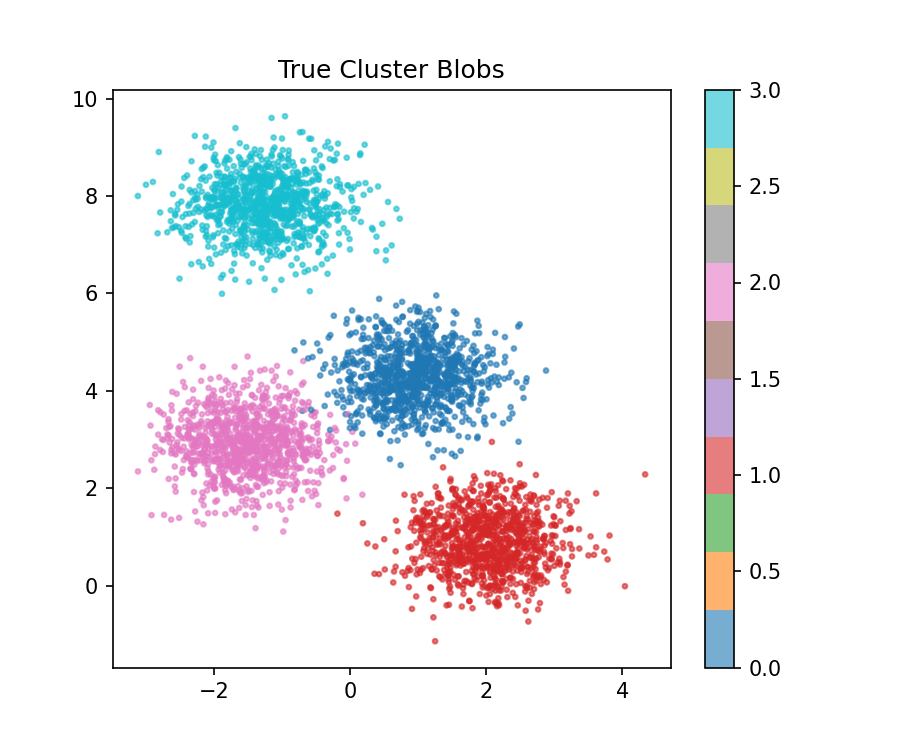

--- K-means Cluster (k=4) ---


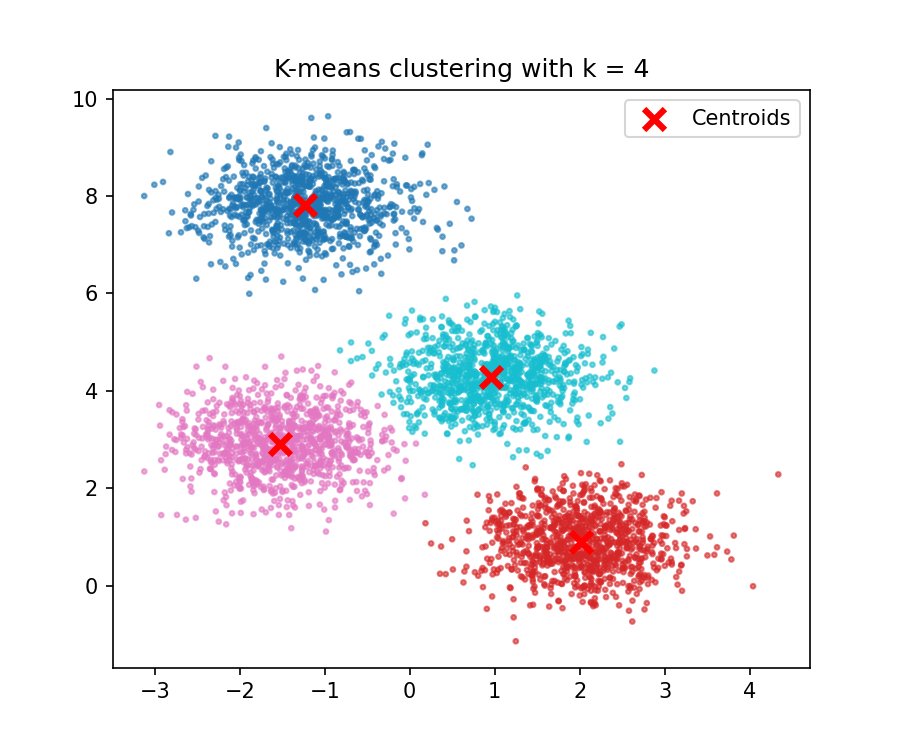

In [ ]:
from IPython.display import Image, display
import os

kmeans_dir = '/content/results/kmeans'
true_plot = os.path.join(kmeans_dir, 'true_labels.png')
k4_plot = os.path.join(kmeans_dir, 'kmeans_k_4.png')

if os.path.exists(true_plot):
    print("--- True Cluster Blobs ---")
    display(Image(true_plot))

if os.path.exists(k4_plot):
    print("--- K-means Cluster (k=4) ---")
    display(Image(k4_plot))

When K increases the amount of groups increase, making your analysis more detailed. However there is a limit to this and at a certain point the amount of clusters provides less than useful data.

## Question 3: Noisy-label SVM and K-NN repair — 40 points

Work in `noisy_classification_template.py`. Helpers for generating clean data and training/evaluating the SVM are provided.

Generate independent training and test sets. Each set contains:

- 1,000 positive examples from a Gaussian with mean **(1, 1)** and covariance **I**.
- 1,000 negative examples from a Gaussian with mean **(-1, -1)** and covariance **3I**.

Keep the test labels clean throughout.

**(a) Noisy-label baseline — 20 points.** Complete `corrupt_training_labels()` and the baseline portion of `run_comparison()`. Independently flip each original positive training label with probability **0.35**, and each original negative training label with probability **0.20**. Apply the probabilities to the original labels so that an example cannot be flipped twice. Train an RBF SVM with **C = 1** and **gamma = 0.01**.

Keep the generated training and test sets fixed, repeat label corruption and training **20 times**, and report the mean accuracy on the clean test set. Use a seed for reproducibility.

**(b) K-NN label repair — 20 points.** Complete `repair_labels_knn()` and the comparison portion of `run_comparison()`. For each training point:

1. Find its **five nearest other training points** using Euclidean distance.
2. Replace its label with the majority of those neighbors' noisy labels.
3. Compute every repaired label from the same original noisy-label array, rather than modifying labels sequentially.

A neighbor-search library is allowed. Five binary votes cannot tie; use a consistent rule if distances tie when selecting neighbors. Train a fresh SVM with the same parameters on the repaired labels. For each trial, use the same features and corrupted labels as the baseline.

Save a CSV with one row per trial and columns `trial`, `baseline_accuracy`, and `knn_accuracy`. Report both mean accuracies and their difference. Briefly explain whether K-NN repair helped and why it might help or hurt. Improvement is not guaranteed. No parameter sweep or additional clustering-based repair experiment is required.

The repair method may use only training features and noisy training labels. Do not pass it clean training labels or test labels. K-NN is a preprocessing step here; the final classifier is an SVM.


When

In [14]:
"""Question 3: noisy-label SVM and K-NN repair (40 points).

Complete the TODOs. Keep test labels clean and use them only for evaluation.
"""

import argparse
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

SVM_C = 1.0
SVM_GAMMA = 0.01
POSITIVE_FLIP_PROBABILITY = 0.35
NEGATIVE_FLIP_PROBABILITY = 0.20


def generate_clean_split(rng, samples_per_class=1000):
    """Return features and labels for one independent clean split.

    Positive class: mean (1, 1), covariance I.
    Negative class: mean (-1, -1), covariance 3I.
    The negative covariance entries are variances, not standard deviations.
    """
    positive = rng.multivariate_normal((1, 1), np.eye(2), samples_per_class)
    negative = rng.multivariate_normal((-1, -1), 3 * np.eye(2), samples_per_class)
    features = np.vstack((positive, negative))
    labels = np.concatenate((np.ones(samples_per_class, dtype=int),
                             -np.ones(samples_per_class, dtype=int)))
    return features, labels


def corrupt_training_labels(clean_labels, rng):
    """Independently flip +1 with probability .35 and -1 with probability .20.

    Select flip probabilities from the ORIGINAL labels. Do not allow a label
    flipped in one direction to be flipped again by the other rule.
    Return a new array, leaving clean_labels unchanged.
    """
    noisy_labels = np.copy(clean_labels)
    pos_indices = np.where(clean_labels == 1)[0]
    neg_indices = np.where(clean_labels == -1)[0]

    # Flip positive labels (+1 -> -1)
    pos_flips = rng.random(size=len(pos_indices)) < POSITIVE_FLIP_PROBABILITY
    noisy_labels[pos_indices[pos_flips]] = -1

    # Flip negative labels (-1 -> +1)
    neg_flips = rng.random(size=len(neg_indices)) < NEGATIVE_FLIP_PROBABILITY
    noisy_labels[neg_indices[neg_flips]] = 1

    return noisy_labels


def repair_labels_knn(train_features, noisy_labels, neighbors):
    """Q3(b): propose a K-NN label-repair method; return repaired labels.

    For this simplified assignment, use 5 neighbors, Euclidean distance,
    and replace each label with the majority label of those neighbors.
    Five binary votes cannot tie; break equal-distance neighbor ties consistently.
    Exclude each point itself from its neighborhood. Base all repairs on
    the original noisy labels, so row ordering does not affect the outcome.
    sklearn.neighbors may be used; from-scratch K-NN is not a source requirement.
    """
    # Setup sklearn NearestNeighbors searching 6 points (1 query + 5 neighbors)
    nbrs = NearestNeighbors(n_neighbors=neighbors + 1, algorithm='brute').fit(train_features)
    distances, indices = nbrs.kneighbors(train_features)

    repaired_labels = np.zeros_like(noisy_labels)
    for i in range(len(train_features)):
        # Exclude the point itself (at index 0)
        neighbor_indices = indices[i, 1:]
        neighbor_labels = noisy_labels[neighbor_indices]

        # Take majority vote
        repaired_labels[i] = 1 if np.sum(neighbor_labels) > 0 else -1

    return repaired_labels


def train_and_evaluate(train_features, train_labels, test_features, test_labels):
    """Train the required RBF SVM and return accuracy on the clean test set."""
    model = SVC(kernel="rbf", C=SVM_C, gamma=SVM_GAMMA)
    model.fit(train_features, train_labels)
    return float(accuracy_score(test_labels, model.predict(test_features)))


def run_comparison(repeats, seed, neighbors, output_path):
    """Q3(a-b), 20 points each: compare the baseline with K-NN label repair."""
    rng = np.random.default_rng(seed)
    train_features, train_labels_clean = generate_clean_split(rng)
    test_features, test_labels_clean = generate_clean_split(rng)

    results = []
    for trial in range(repeats):
        # Corrupt training labels
        train_labels_noisy = corrupt_training_labels(train_labels_clean, rng)

        # Baseline
        baseline_acc = train_and_evaluate(train_features, train_labels_noisy, test_features, test_labels_clean)

        # K-NN Repair
        train_labels_repaired = repair_labels_knn(train_features, train_labels_noisy, neighbors)
        knn_acc = train_and_evaluate(train_features, train_labels_repaired, test_features, test_labels_clean)

        results.append({
            'trial': trial,
            'baseline_accuracy': baseline_acc,
            'knn_accuracy': knn_acc
        })

    # Save results to CSV
    df_results = pd.DataFrame(results)
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    df_results.to_csv(output_path, index=False)

    # Report summaries
    mean_baseline = df_results['baseline_accuracy'].mean()
    mean_knn = df_results['knn_accuracy'].mean()
    print(f"Results saved to {output_path}")
    print(f"Mean Baseline Accuracy: {mean_baseline:.4f}")
    print(f"Mean K-NN Repaired Accuracy: {mean_knn:.4f}")
    print(f"Accuracy Improvement: {mean_knn - mean_baseline:+.4f}")


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--repeats", type=int, default=20)
    parser.add_argument("--seed", type=int, default=0)
    parser.add_argument("--neighbors", type=int, default=5,
                        choices=(5,), help="Use five neighbors for this assignment.")
    parser.add_argument("--output", type=Path,
                        default=Path("results/noise_comparison.csv"))

    import sys
    if "ipykernel" in sys.modules:
        args = parser.parse_args([])
    else:
        args = parser.parse_args()

    run_comparison(args.repeats, args.seed, args.neighbors, args.output)


if __name__ == "__main__":
    main()

Results saved to results/noise_comparison.csv
Mean Baseline Accuracy: 0.8280
Mean K-NN Repaired Accuracy: 0.8644
Accuracy Improvement: +0.0364


KNN repair was useful because it increased the accuracy.

In [15]:
import shutil
from pathlib import Path

# Define paths
target_dir = Path('/content/242 assignment 3')
target_dir.mkdir(parents=True, exist_ok=True)

# List of files/folders to move
paths_to_move = [
    Path('/content/svm_data.png'),
    Path('/content/results')
]

for path in paths_to_move:
    if path.exists():
        dest = target_dir / path.name
        # If a directory with the same name already exists in the destination, remove it first to avoid collision
        if dest.exists():
            if dest.is_dir():
                shutil.rmtree(dest)
            else:
                dest.unlink()

        shutil.move(str(path), str(target_dir))
        print(f"Moved: {path.name} -> {target_dir.name}/{path.name}")
    else:
        print(f"Path not found (already moved or doesn't exist): {path}")

Moved: svm_data.png -> 242 assignment 3/svm_data.png
Moved: results -> 242 assignment 3/results


In [17]:
from google.colab import drive
import shutil
from pathlib import Path

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define source and destination paths
source_dir = Path('/content/242 assignment 3')
destination_dir = Path('/content/drive/MyDrive/242 assignment 3')

# 3. Copy files to Google Drive
if source_dir.exists():
    if destination_dir.exists():
        shutil.rmtree(destination_dir)
    shutil.copytree(source_dir, destination_dir)
    print(f"\nSuccess! All files successfully copied to Google Drive at: Google Drive > My Drive > 242 assignment 3")
else:
    print("Error: Local '242 assignment 3' folder not found.")

Mounted at /content/drive

Success! All files successfully copied to Google Drive at: Google Drive > My Drive > 242 assignment 3
